# Лабораторная работа №3: Свойства оценок, полученных методом моментов

1. Метод моментов (ММ) для $U[a, b]$, генеральное распределение $U[0, 1]$; график оценок от $n$.
2. Обобщённый метод моментов (ОММ) с 3, 5, 7 моментами; веса, снижающие дисперсию по сравнению с ММ.
3. СКО оценок от $n$ по $10^3$ выборкам; выводы.
4. То же для $\mathrm{Exp}(\lambda)$, генеральное распределение $\mathrm{Exp}(1)$.

## Метод

**ММ:** решаем $\mu_j(\theta) = \hat m_j$, $j = 1, \dots, p$ ($p$ — число параметров).

**ОММ:** $\hat\theta = \arg\min_\theta g(\theta)^\top W g(\theta)$, где $g_j = \hat m_j - \mu_j(\theta)$, $j = 1, \dots, k$, $k > p$.
Асимптотически наименьшую дисперсию даёт $W = S^{-1}$, $S = \operatorname{cov}(\text{моментных функций})$; при этом
$V_{\text{ОММ}}^{(k)} \preceq V_{\text{ММ}}$ и с ростом $k$ дисперсия не растёт.

**Предлагаемые веса и оптимизатор (двухшаговый ОММ).**
Шаг 1 — оценка ММ $\hat\theta_0$. Шаг 2 — стандартизуем выборку так, чтобы при $\theta = \hat\theta_0$ она имела стандартное распределение,
и берём моменты **ортогональных полиномов** этого распределения вместо $x^j$:

| | стандартизация | моментные функции | $S(\hat\theta_0)$ | веса $W = S^{-1}$ |
|---|---|---|---|---|
| $U[a,b]$ | $z = \dfrac{x - c_0}{h_0} \sim U[-1,1]$ | Лежандр $P_j(z)$ | $\mathrm{diag}\,\frac{1}{2j+1}$ | $\mathrm{diag}(2j+1)$ |
| $\mathrm{Exp}(\lambda)$ | $z = \hat\lambda_0 x \sim \mathrm{Exp}(1)$ | Лагерр $L_j(z)$ | $I$ | $I$ |

Полиномы степени $\le k$ — линейная комбинация $x, \dots, x^k$, поэтому оценка совпадает с ОММ на обычных моментах с $W = S(\hat\theta_0)^{-1}$,
но задача становится взвешенным МНК с идеальной обусловленностью (у матрицы $S$ для $x^1, \dots, x^7$ число обусловленности $\sim 10^{9}$).
Минимизация — векторизованный метод Гаусса–Ньютона сразу по всем $10^3$ выборкам.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
N_MC = 10**3
K_LIST = [3, 5, 7]
N_TRAJ = np.unique(np.logspace(1, 4, 40).astype(int))
N_MC_SIZES = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
COLORS = {'ММ': 'black', 'ОММ, k=3': 'tab:blue', 'ОММ, k=5': 'tab:orange', 'ОММ, k=7': 'tab:green'}

plt.rcParams['figure.dpi'] = 110


def gauss_newton(model, m, t, valid, n_iter=100, tol=1e-10):
    """min ||m - mu(t)||² для каждой строки m; model(t) -> (mu, J)."""
    t = t.astype(float).copy()
    sse = lambda tt, mm: ((mm - model(tt)[0]) ** 2).sum(1)
    q = sse(t, m)
    act = np.arange(len(t))
    for _ in range(n_iter):
        if act.size == 0:
            break
        mu, J = model(t[act])
        Jt = J.transpose(0, 2, 1)
        step = np.linalg.solve(Jt @ J, Jt @ (m[act] - mu)[..., None])[..., 0]
        lam, done = np.ones(len(act)), np.zeros(len(act), bool)
        for _ in range(40):
            cand = t[act] + lam[:, None] * step
            ok = valid(cand) & ~done
            qn = np.full(len(act), np.inf)
            if ok.any():
                qn[ok] = sse(cand[ok], m[act][ok])
            good = ok & (qn <= q[act])
            t[act[good]], q[act[good]] = cand[good], qn[good]
            done |= good
            if done.all():
                break
            lam[~done] /= 2
        act = act[done & (np.abs(lam[:, None] * step).max(1) > tol)]
    return t


def estimate_all(x, mm, gmm):
    return {'ММ': mm(x), **{f'ОММ, k={k}': gmm(x, k) for k in K_LIST}}


def plot_trajectories(x, mm, gmm, true, names, title):
    est = [estimate_all(x[None, :n], mm, gmm) for n in N_TRAJ]
    fig, axes = plt.subplots(1, len(names), figsize=(6.5 * len(names), 4), squeeze=False)
    for i, ax in enumerate(axes[0]):
        for name, color in COLORS.items():
            ax.plot(N_TRAJ, [e[name][0, i] for e in est], color=color, lw=2 if name == 'ММ' else 1.2, label=name)
        ax.axhline(true[i], color='red', ls=':', label='истинное значение')
        ax.set(xscale='log', xlabel='n', ylabel=names[i], title=f'{title}: оценка {names[i]}')
        ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def mc_std(sampler, mm, gmm, seed):
    rng = np.random.default_rng(seed)
    return {n: {name: v.std(0, ddof=1) for name, v in estimate_all(sampler(rng, (N_MC, n)), mm, gmm).items()}
            for n in N_MC_SIZES}


def plot_std(sd, names, title, bound=None):
    fig, axes = plt.subplots(1, len(names), figsize=(6.5 * len(names), 4.2), squeeze=False)
    ns = np.array(N_MC_SIZES)
    for i, ax in enumerate(axes[0]):
        for name, color in COLORS.items():
            ax.plot(ns, [sd[n][name][i] for n in ns], 'o-', color=color, ms=4, label=name)
        if bound is not None:
            ax.plot(ns, bound / np.sqrt(ns), 'r:', label='граница Рао–Крамера')
        ax.set(xscale='log', yscale='log', xlabel='n', ylabel='СКО', title=f'{title}: СКО оценки {names[i]}')
        ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print('СКО / СКО(ММ):')
    print(f'{"n":>6}' + ''.join(f'{name:>11}' for name in COLORS))
    for n in N_MC_SIZES:
        print(f'{n:>6}' + ''.join(f'{(sd[n][name] / sd[n]["ММ"]).mean():>11.3f}' for name in COLORS))

---
# Часть I. Равномерное распределение $U[a, b]$

**ММ:** $\mathbb{E}X = \frac{a+b}{2}$, $\mathbb{D}X = \frac{(b-a)^2}{12}$ $\Rightarrow$
$\hat a = \bar x - \sqrt{3}\,s$, $\hat b = \bar x + \sqrt{3}\,s$, где $s^2 = \frac1n\sum (x_i - \bar x)^2$.

**ОММ:** $c_0 = \frac{\hat a + \hat b}{2}$, $h_0 = \frac{\hat b - \hat a}{2}$, $z = \frac{x - c_0}{h_0}$. Если $z \sim U[\alpha, \beta]$, то
$$
\mathbb{E}P_j(z) = \frac{Q_j(\beta) - Q_j(\alpha)}{\beta - \alpha}, \qquad Q_j = \frac{P_{j+1} - P_{j-1}}{2j+1}, \qquad
\frac{\partial \mu_j}{\partial \alpha} = \frac{\mu_j - P_j(\alpha)}{\beta - \alpha}, \quad
\frac{\partial \mu_j}{\partial \beta} = \frac{P_j(\beta) - \mu_j}{\beta - \alpha}.
$$
Минимизируем $\sum_{j=1}^k (2j+1)\bigl(\overline{P_j(z)} - \mu_j(\alpha, \beta)\bigr)^2$, затем $\hat a = c_0 + h_0\hat\alpha$, $\hat b = c_0 + h_0\hat\beta$.

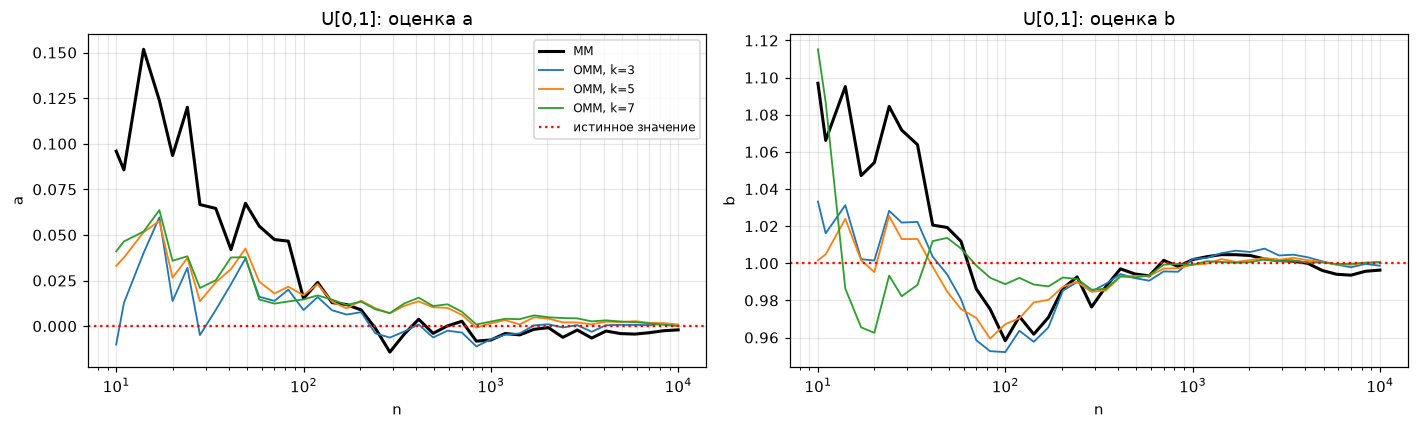

In [2]:
def legendre(z, k):
    """P_0, ..., P_{k+1} по рекуррентной формуле."""
    P = [np.ones_like(z), z]
    for j in range(1, k + 1):
        P.append(((2 * j + 1) * z * P[j] - j * P[j - 1]) / (j + 1))
    return np.stack(P, -1)


def legendre_means(z, k):
    """Средние P_1(z), ..., P_k(z) по последней оси без хранения всех полиномов."""
    p_prev, p, out = np.ones_like(z), z, []
    for j in range(1, k + 1):
        out.append(p.mean(-1))
        p_prev, p = p, ((2 * j + 1) * z * p - j * p_prev) / (j + 1)
    return np.stack(out, -1)


def mm_uniform(x):
    s = np.sqrt(3 * x.var(-1))
    return np.stack([x.mean(-1) - s, x.mean(-1) + s], -1)


def gmm_uniform(x, k):
    c, h = x.mean(-1), np.sqrt(3 * x.var(-1))
    j = np.arange(1, k + 1)
    w = np.sqrt(2 * j + 1)
    m = w * legendre_means((x - c[:, None]) / h[:, None], k)

    def model(t):
        Pa, Pb = legendre(t[:, 0], k), legendre(t[:, 1], k)
        d = (t[:, 1] - t[:, 0])[:, None]
        mu = ((Pb[:, j + 1] - Pb[:, j - 1]) - (Pa[:, j + 1] - Pa[:, j - 1])) / (2 * j + 1) / d
        J = np.stack([(mu - Pa[:, j]) / d, (Pb[:, j] - mu) / d], -1)
        return w * mu, w[:, None] * J

    t = gauss_newton(model, m, np.tile([-1.0, 1.0], (len(x), 1)), lambda t: t[:, 1] > t[:, 0])
    return c[:, None] + h[:, None] * t


rng = np.random.default_rng(SEED)
plot_trajectories(rng.uniform(0, 1, N_TRAJ[-1]), mm_uniform, gmm_uniform, [0, 1], ['a', 'b'], 'U[0,1]')

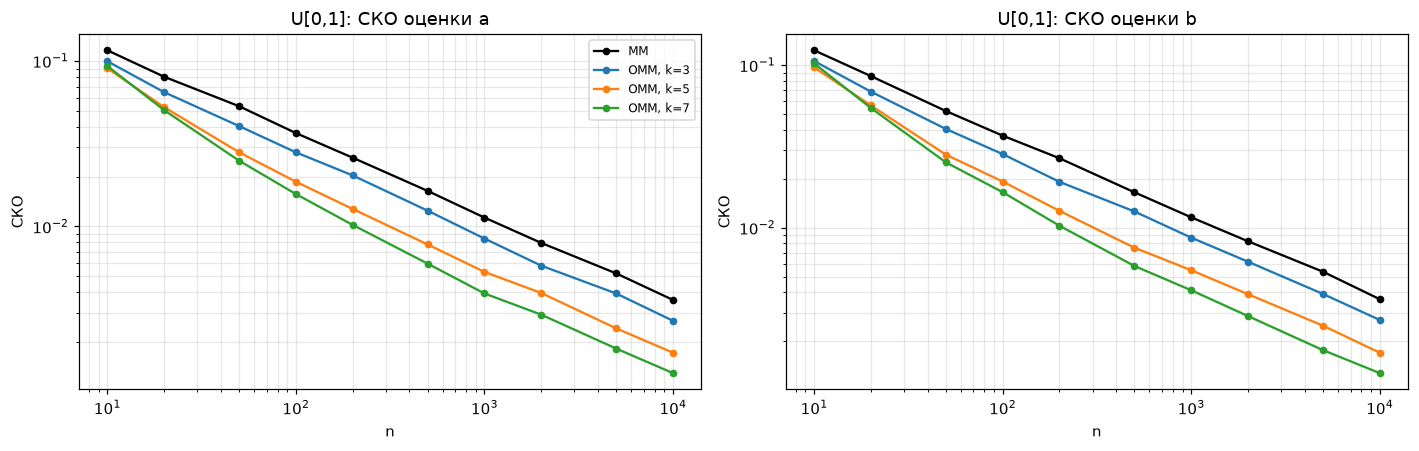

СКО / СКО(ММ):
     n         ММ   ОММ, k=3   ОММ, k=5   ОММ, k=7
    10      1.000      0.859      0.782      0.817
    20      1.000      0.805      0.657      0.632
    50      1.000      0.767      0.533      0.476
   100      1.000      0.767      0.515      0.438
   200      1.000      0.749      0.482      0.388
   500      1.000      0.761      0.465      0.358
  1000      1.000      0.748      0.471      0.352
  2000      1.000      0.739      0.485      0.357
  5000      1.000      0.743      0.465      0.340
 10000      1.000      0.747      0.474      0.356


In [3]:
sd_unif = mc_std(lambda rng, size: rng.uniform(0, 1, size), mm_uniform, gmm_uniform, SEED + 1)
plot_std(sd_unif, ['a', 'b'], 'U[0,1]')

### Выводы по $U[a, b]$

- Все оценки состоятельны: с ростом $n$ сходятся к $(0, 1)$, СКО убывает как $1/\sqrt n$.
- ОММ с весами $W = S(\hat\theta_0)^{-1}$ точнее ММ при любом $k$, и **с ростом $k$ точность растёт**: при больших $n$ СКО составляет $\approx 0{,}75$ (k=3), $0{,}47$ (k=5) и $0{,}35$ (k=7) от СКО ММ — это совпадает с асимптотической теорией $\sqrt{V^{(k)}_{\text{ОММ}} / V_{\text{ММ}}}$.
- Высокие моменты несут информацию о границах интервала, поэтому каждый добавленный момент уточняет $a$ и $b$.
- При очень малых выборках ($n = 10$) 7 моментов по 10 точкам — уже слишком много: оценка $k = 7$ не лучше $k = 5$. Чем больше $n$, тем больше моментов имеет смысл использовать.

---
# Часть II. Экспоненциальное распределение $\mathrm{Exp}(\lambda)$

**ММ:** $\mathbb{E}X = 1/\lambda \Rightarrow \hat\lambda_0 = 1/\bar x$. Это же оценка максимального правдоподобия.

**ОММ:** $z = \hat\lambda_0 x$. Если $X \sim \mathrm{Exp}(\lambda)$, то $z \sim \mathrm{Exp}(r)$, $r = \lambda / \hat\lambda_0$, и из производящей функции полиномов Лагерра
$$
\mu_j(r) = \mathbb{E} L_j(z) = \Bigl(1 - \frac{1}{r}\Bigr)^j, \qquad
\frac{\partial \mu_j}{\partial r} = \frac{j}{r^2}\Bigl(1 - \frac{1}{r}\Bigr)^{j-1}.
$$
Минимизируем $\sum_{j=1}^k \bigl(\overline{L_j(z)} - \mu_j(r)\bigr)^2$, затем $\hat\lambda = \hat\lambda_0 \hat r$.

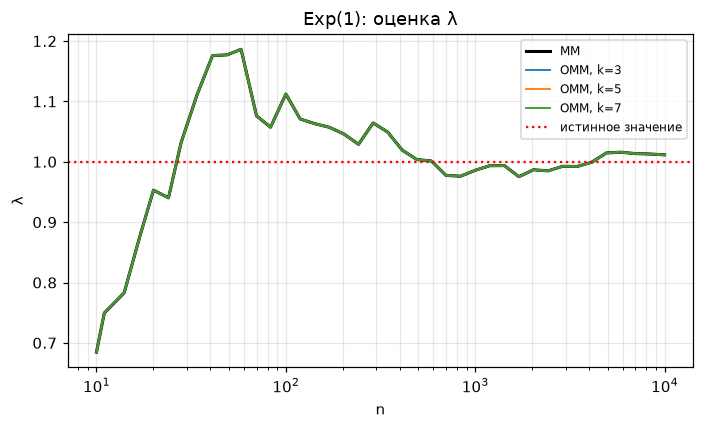

max |ОММ − ММ| при n = 10^4: 2.220446049250313e-16


In [4]:
def laguerre_means(z, k):
    """Средние L_1(z), ..., L_k(z) по последней оси."""
    p_prev, p, out = np.ones_like(z), 1 - z, []
    for j in range(1, k + 1):
        out.append(p.mean(-1))
        p_prev, p = p, ((2 * j + 1 - z) * p - j * p_prev) / (j + 1)
    return np.stack(out, -1)


def mm_exp(x):
    return 1 / x.mean(-1, keepdims=True)


def gmm_exp(x, k):
    lam0 = mm_exp(x)
    m = laguerre_means(lam0 * x, k)
    j = np.arange(1, k + 1)

    def model(r):
        u = 1 - 1 / r
        return u ** j, (j * u ** (j - 1) / r ** 2)[..., None]

    r = gauss_newton(model, m, np.ones((len(x), 1)), lambda r: r[:, 0] > 0)
    return lam0 * r


rng = np.random.default_rng(SEED)
x_exp = rng.exponential(1.0, N_TRAJ[-1])
plot_trajectories(x_exp, mm_exp, gmm_exp, [1], ['λ'], 'Exp(1)')

est = estimate_all(x_exp[None, :], mm_exp, gmm_exp)
print('max |ОММ − ММ| при n = 10^4:', max(abs(est[f'ОММ, k={k}'] - est['ММ']).max() for k in K_LIST))

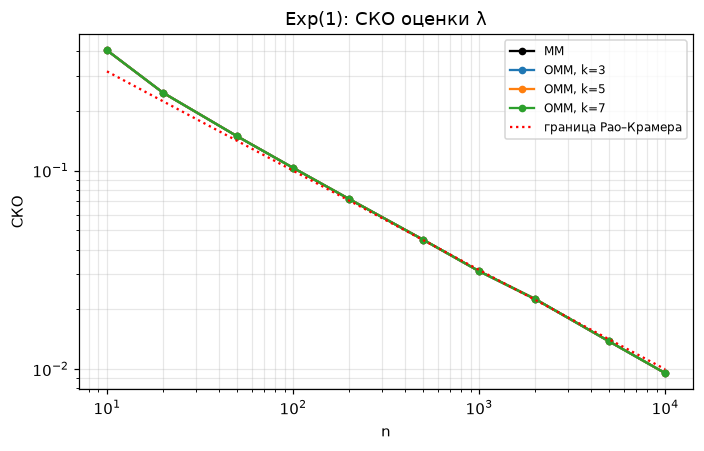

СКО / СКО(ММ):
     n         ММ   ОММ, k=3   ОММ, k=5   ОММ, k=7
    10      1.000      1.000      1.000      1.000
    20      1.000      1.000      1.000      1.000
    50      1.000      1.000      1.000      1.000
   100      1.000      1.000      1.000      1.000
   200      1.000      1.000      1.000      1.000
   500      1.000      1.000      1.000      1.000
  1000      1.000      1.000      1.000      1.000
  2000      1.000      1.000      1.000      1.000
  5000      1.000      1.000      1.000      1.000
 10000      1.000      1.000      1.000      1.000


In [5]:
sd_exp = mc_std(lambda rng, size: rng.exponential(1.0, size), mm_exp, gmm_exp, SEED + 2)
plot_std(sd_exp, ['λ'], 'Exp(1)', bound=1.0)

### Выводы по $\mathrm{Exp}(\lambda)$

- $\hat\lambda = 1/\bar x$ состоятельна; её СКО с ростом $n$ выходит на границу Рао–Крамера $\lambda/\sqrt n$, т.е. ММ здесь уже **эффективная** оценка (совпадает с ОМП).
- ОММ с оптимальными весами при любом $k$ совпадает с ММ с машинной точностью: $\overline{L_1(z)} = 1 - \hat\lambda_0 \bar x = 0$, и оптимальная комбинация моментов использует только первый ($\bar x$ — достаточная статистика). Все кривые СКО лежат друг на друге.
- Добавление моментов точность не ухудшает, но и улучшить её нельзя: ниже границы Рао–Крамера несмещённая (асимптотически) оценка не опускается.